# 04 — The enhanced dataset: structure, checks and cleaning

**What changed:** the line's enhanced dataset is now **`enhance-v2`** (pinned in `enhanced/latest.json`). It adds data from
outside the challenge to the weather record we cleaned in notebooks 01–02 and in `clean-v1`:

- **City facts** (`static/city_static.csv`, the same file as in `enhance-v1`): elevation, distance to the ocean coast and
  land cover around each of the 210 stations. Fixed facts, allowed from any year.
- **Ocean indices** (`ocean/origin-YYYY/`): monthly and annual sea-surface temperature (SST) for three ocean boxes
  (Niño 3.4, North Pacific, North Atlantic) from NOAA ERSSTv5, one snapshot per origin 1979–2018, each ending in December of
  its origin and normalised on the 30 years ending there.

The challenge weather data itself did not change: the Hugging Face dataset is still at revision `bbbdebd`.

**Same process as before:** understand every table and column, test it for flaws, decide an action for each flaw with
evidence, and write a cleaned, model-ready version. The cleaning code is
[`cleaning_enhanced.py`](../../src/protostar_challenge/cleaning_enhanced.py), run by `scripts/04_clean_enhanced.py`;
this notebook shows the evidence. Documentation: [`documentation/10-enhanced.md`](../../documentation/10-enhanced.md).

**Data rule.** Nothing here reads weather after 2018. Where the notebook compares the new inputs with the targets
(sections 4 and 7), it uses years up to **2004** only, so no year scored at the sealed assessment origins (2004, 2011) shapes
a choice.

**Needs the releases locally:** `uv run python scripts/line.py pull enhance-v1 enhance-v2`. They are not on GitHub, so this
notebook does not run on Colab.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "code" / "common.py").exists())
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "code")]
from common import METRICS, assert_no_post_cutoff, load_valid_annual  # noqa: E402
from protostar_challenge import cleaning_enhanced as ce  # noqa: E402

RELEASES = ROOT / "data/processed/releases"
V1, V2 = RELEASES / "enhance-v1", RELEASES / "enhance-v2"
EXPLORE_END = 2004   # last year any comparison with the targets may use

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
warnings.filterwarnings("ignore", category=RuntimeWarning)
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#898781", "#e1e0d9"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6", "#e34948"]
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 90,
    "font.size": 10, "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Arial", "DejaVu Sans"],
    "axes.edgecolor": MUTED, "axes.grid": True, "grid.color": GRID, "axes.spines.top": False,
    "axes.spines.right": False, "axes.prop_cycle": mpl.cycler(color=SERIES)})
for path in (V1, V2):
    assert (path / "release.json").is_file(), f"run: uv run python scripts/line.py pull {path.name}"
print("Repo root:", ROOT)

Repo root: D:\Projects_Ad Astra\Project_27_ProtoStar Challenge\wt\clean


## 1. What is in the release

Every release is immutable and hashed. The table shows each file group, its size, and whether it is
**gate-eligible**, meaning it may be used in an official (gated) score.

In [2]:
releases = {p.name: json.loads((p / "release.json").read_text()) for p in (V1, V2)}
rows = []
for rid, m in releases.items():
    groups = {}
    for name, rec in m["files"].items():
        key = "ocean/origin-YYYY/*" if name.startswith("ocean/") else name.split("/")[0] + ("/" if "/" in name else "")
        g = groups.setdefault(key, [0, 0])
        g[0] += 1
        g[1] += rec["size"]
    for key, (n, size) in sorted(groups.items()):
        rows.append({"release": rid, "group": key, "files": n, "MB": size / 1e6, "gate_eligible": m["gate_eligible"]})
display(pd.DataFrame(rows))
print("enhance-v2 note:", releases["enhance-v2"]["note"])
same = ce.sha256(V1 / "static/city_static.csv") == ce.sha256(V2 / "static/city_static.csv")
print("city_static.csv identical in enhance-v1 and enhance-v2:", same)

,release,group,files,MB,gate_eligible
0,enhance-v1,provenance.json,1,0.080,True
1,enhance-v1,quality.json,1,0.001,True
2,enhance-v1,schema.json,1,0.002,True
3,enhance-v1,sources/,641,8.684,True
4,enhance-v1,static/,1,0.082,True
5,enhance-v2,ocean/origin-YYYY/*,80,2.877,False
6,enhance-v2,provenance.json,1,0.014,False
7,enhance-v2,quality.json,1,0.001,False
8,enhance-v2,schema.json,1,0.005,False
9,enhance-v2,sources/,6,7.747,False


enhance-v2 note: enhance-v2: cumulative city facts plus three NOAA ERSSTv5 regional SST indices, January 1950 to December 2018. Forty origin-specific monthly/annual snapshots use training-only 30-year calendar-month references; all tables reproduce offline. Exploratory: not gate-eligible because pre-origin reconstruction/calibration vintage is not certified. No model, target labels, currents, solar or climate projections.
city_static.csv identical in enhance-v1 and enhance-v2: True


`enhance-v2` is **not gate-eligible**. Its ocean values come from a modern reconstruction (ERSSTv5) that was fitted using
data from after many of our origins. Cutting rows at the origin does not remove that, and cleaning cannot fix it. The city
facts are the same bytes as in `enhance-v1`, which is gate-eligible. So the cleaned city table below is built from
`enhance-v1`, and it can go into a gate-eligible release.

## 2. City facts: structure and data dictionary

In [3]:
static = pd.read_csv(V1 / "static/city_static.csv", dtype={"elevation_acquisition_date_raw": str})
schema = json.loads((V1 / "schema.json").read_text())
print(static.shape, "| one row per city, key city_id |", static["city_id"].is_unique)


def unit(col):
    if col.endswith("_km"):
        return "km"
    if col.endswith("_m"):
        return "m"
    if col.endswith("_fraction_1km"):
        return "fraction of 1 km radius"
    if col in ("lat", "lon", "station_catalog_lat", "station_catalog_lon"):
        return "degrees"
    return ""


dictionary = pd.DataFrame({
    "dtype": static.dtypes.astype(str), "unit": [unit(c) for c in static.columns],
    "missing": static.isna().sum(), "unique": static.nunique(),
    "min": [static[c].min() if static[c].dtype.kind in "if" else "" for c in static.columns],
    "max": [static[c].max() if static[c].dtype.kind in "if" else "" for c in static.columns]})
dictionary["constant"] = dictionary["unique"] == 1
display(dictionary)
print("Limitations stated by the source:")
for line in schema["limitations"]:
    print(" -", line)

(210, 31) | one row per city, key city_id | True


,dtype,unit,missing,unique,min,max,constant
city_id,str,,0,210,,,False
name,str,,0,210,,,False
lat,float64,degrees,0,210,24.555,48.561,False
lon,float64,degrees,0,209,-124.237,-70.300,False
station_catalog_lat,float64,degrees,0,210,24.557,48.559,False
station_catalog_lon,float64,degrees,0,210,-124.238,-70.305,False
station_catalog_elevation_m,float64,m,0,200,0.300,"2,133.300",False
elevation_coordinate_offset_km,float64,km,0,159,0.000,11.104,False
elevation_m,float64,m,0,210,0.462,"2,133.280",False
elevation_resolution_m,float64,m,0,5,0.000,1.000,False


Limitations stated by the source:
 - 2021 structural snapshot does not reconstruct historical urban development
 - Tree class fraction is not percent canopy or vegetation health
 - Built class is not impervious fraction
 - Current station coordinates and ground elevations may differ from earlier record segments
 - Numeric class codes are categorical, not an ordered continuous variable


**Reading the dictionary:**

- **Six columns are constant** (`elevation_source`, `coast_sampling_error_bound_km`, `landcover_year`,
  `landcover_valid_fraction_1km`, and the snow/ice and moss/lichen fractions, all 0). A model can learn nothing from them.
- **The two `landcover_*_class` columns are codes** (10 tree, 30 grass, 50 built, …), not numbers with an order. Treat them as
  categories.
- **The land-cover fractions add up to 1**, so any one of them follows from the others. A linear model should leave one out.
- **The station's own 10 m pixel class is noisy.** Spokane's pixel is "bare" although 73 % of the area around it is
  built. The 1 km fractions describe the surroundings better.
- `elevation_acquisition_date_raw` mixes formats (`9/1/2017`, epoch milliseconds, and `0/6/2020` with month 0). The parsed
  `elevation_acquisition_date` handles all of them and marks 19 as `unknown`. It is metadata, not a feature.

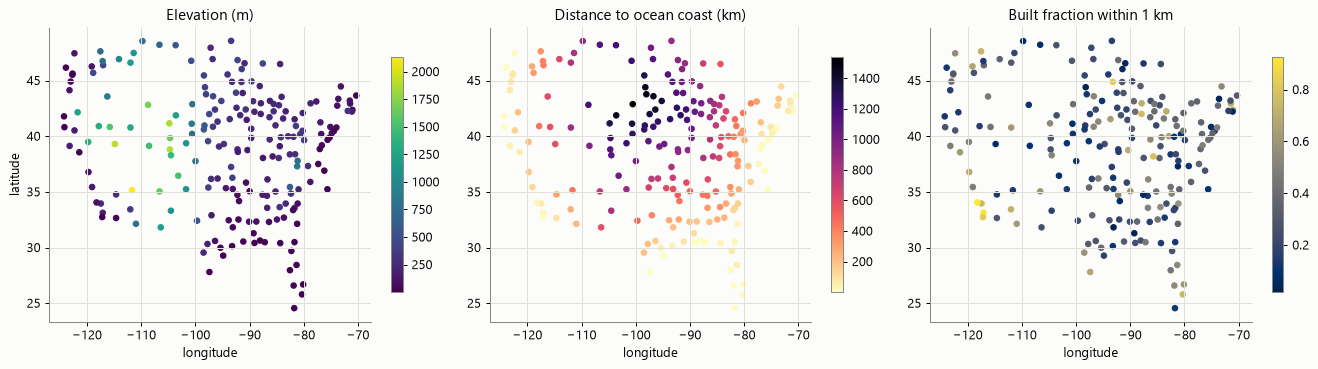

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (col, label, cmap) in zip(axes, [("elevation_m", "Elevation (m)", "viridis"),
                                         ("distance_to_ocean_coast_km", "Distance to ocean coast (km)", "magma_r"),
                                         ("landcover_built_fraction_1km", "Built fraction within 1 km", "cividis")]):
    sc = ax.scatter(static["lon"], static["lat"], c=static[col], cmap=cmap, s=18)
    fig.colorbar(sc, ax=ax, shrink=0.8)
    ax.set_title(label)
    ax.set_xlabel("longitude")
axes[0].set_ylabel("latitude")
plt.tight_layout()
plt.show()

## 3. City facts: checks for flaws

In [5]:
cities = pd.read_csv(ROOT / "data/city_info.csv")
joined = static.merge(cities, on="city_id", suffixes=("", "_challenge"), validate="one_to_one")
fractions = [c for c in static.columns if c.endswith("_fraction_1km") and "valid" not in c]
checks = {
    "same 210 city_ids as data/city_info.csv": set(static.city_id) == set(cities.city_id),
    "names match": (joined["name"] == joined["name_challenge"]).all(),
    "coordinates match the challenge coordinates": np.allclose(joined["lat"], joined["lat_challenge"])
                                                   and np.allclose(joined["lon"], joined["lon_challenge"]),
    "land-cover fractions sum to 1": np.allclose(static[fractions].sum(axis=1), 1, atol=1e-6),
    "no missing values (except the raw date string)": not static.drop(columns="elevation_acquisition_date_raw").isna().any().any()}
display(pd.Series(checks, name="passes").to_frame())

,passes
same 210 city_ids as data/city_info.csv,True
names match,True
coordinates match the challenge coordinates,True
land-cover fractions sum to 1,True
no missing values (except the raw date string),True


The table joins cleanly. The flaws are in three columns.

### 3a. Elevation resolution: degrees in a metres column

`elevation_resolution_m` should be the size of the elevation grid cell in metres. For 15 cities it is 0.0000309 or
0.0000926: those are 1/9 and 1/3 arc-second written in **degrees**, about 3.4 m and 10.3 m. **Action:** convert to metres.

In [6]:
res = static["elevation_resolution_m"]
display(res.round(8).value_counts().rename("cities").to_frame())
display(static.loc[res < ce.DEGREES_LIMIT, ["name", "elevation_resolution_m"]]
        .assign(in_metres=lambda d: d["elevation_resolution_m"] * ce.METRES_PER_DEGREE).head(6))

,cities
elevation_resolution_m,
1.000,194
0.000,9
0.000,6
1.000,1


,name,elevation_resolution_m,in_metres
26,Stillwater,0.000,3.436
33,Tampa,0.000,3.436
39,Raleigh,0.000,3.436
135,Ely,0.000,10.307
154,GreatFalls,0.000,10.307
157,Missoula,0.000,10.307


### 3b. Two elevations that disagree

The release has two elevations per city. `elevation_m` is the USGS ground elevation at the challenge coordinate, and
`station_catalog_elevation_m` is the NOAA station catalog's value. They agree within 2 m for half the cities. At 15 cities
they differ by more than 30 m, and in all 15 the catalog value is the higher one. 30 m of height is about 0.2 °C (0.35 °F)
at the standard lapse rate, which is roughly the size of the skill gains we are working with.

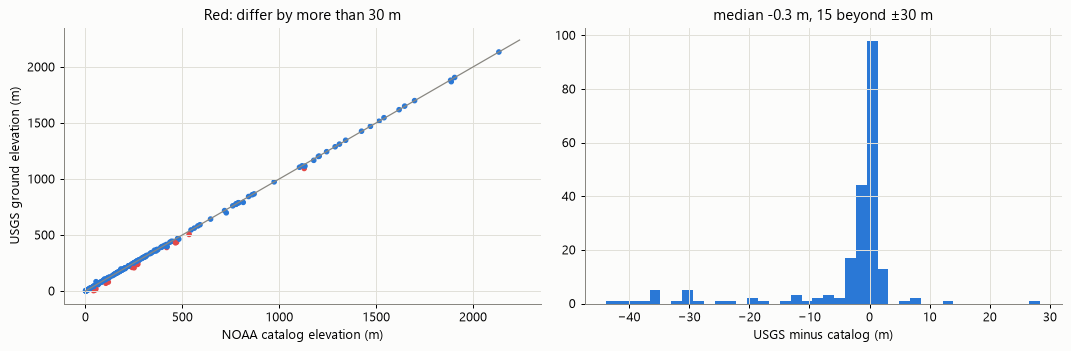

,name,elevation_m,station_catalog_elevation_m,elevation_coordinate_offset_km,diff_m
106,GreenBay,207.109,250.900,0.033,-43.791
58,Jacksonville,7.835,48.800,0.033,-40.965
20,LakeCharles,3.061,41.800,0.033,-38.739
65,Shreveport,79.680,118.000,0.036,-38.320
56,ColumbiaSC,68.713,105.200,0.028,-36.487
174,Tallahassee,18.459,53.900,0.000,-35.441
130,Amarillo,"1,093.530","1,128.700",0.027,-35.170
202,Marquette,429.676,464.800,0.000,-35.124
107,Duluth,435.087,470.000,0.000,-34.913
37,CorpusChristi,11.723,43.300,11.104,-31.577


In [7]:
diff = static["elevation_m"] - static["station_catalog_elevation_m"]
far = diff.abs() > ce.ELEVATION_DISAGREE_M
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(static["station_catalog_elevation_m"], static["elevation_m"], s=12, c=np.where(far, SERIES[6], SERIES[0]))
lim = [0, static["elevation_m"].max() * 1.05]
ax[0].plot(lim, lim, color=MUTED, lw=1)
ax[0].set_xlabel("NOAA catalog elevation (m)")
ax[0].set_ylabel("USGS ground elevation (m)")
ax[0].set_title("Red: differ by more than 30 m")
ax[1].hist(diff, bins=40, color=SERIES[0])
ax[1].set_xlabel("USGS minus catalog (m)")
ax[1].set_title(f"median {diff.median():.1f} m, {int(far.sum())} beyond ±30 m")
plt.tight_layout()
plt.show()
display(static.loc[far, ["name", "elevation_m", "station_catalog_elevation_m", "elevation_coordinate_offset_km"]]
        .assign(diff_m=diff[far]).sort_values("diff_m"))

The large differences occur where the two coordinates are within 40 m of each other (offset ≈ 0.03 km), so they are not
explained by the coordinate. The USGS values match the published field elevations of the airports these stations sit at
to within a few metres (for example Green Bay ≈ 212 m, Indianapolis ≈ 243 m, Duluth ≈ 435 m). The catalog values are probably from an older
instrument site or barometer height. **Action:** keep `elevation_m` (USGS) as the feature, do not use the catalog
elevation, and flag the 15 cities (`elevation_catalog_disagrees`).

### 3c. Three challenge coordinates are not at the station

All facts are measured at the challenge coordinate. For most cities it is within 1 km of the catalog station. For three
cities it is more than 3 km away, beyond the ~1.9 km error of a coordinate given to the arc-minute:

In [8]:
offset = static.set_index("name")["elevation_coordinate_offset_km"].sort_values(ascending=False)
display(static.loc[static["elevation_coordinate_offset_km"] > ce.COORDINATE_OFFSET_KM,
                   ["name", "lat", "lon", "station_catalog_lat", "station_catalog_lon", "elevation_coordinate_offset_km",
                    "distance_to_ocean_coast_km", "landcover_water_fraction_1km"]])
print("Next largest offsets (km):", offset.iloc[3:8].round(2).to_dict())

,name,lat,lon,station_catalog_lat,station_catalog_lon,elevation_coordinate_offset_km,distance_to_ocean_coast_km,landcover_water_fraction_1km
37,CorpusChristi,27.800,-97.400,27.784,-97.511,11.104,0.617,0.032
170,LosAngeles,34.051,-118.235,34.024,-118.291,5.982,22.368,0.001
200,Chicago,41.995,-87.934,41.960,-87.932,3.862,979.485,0.002


Next largest offsets (km): {'Baltimore': 2.83, 'Reno': 2.67, 'Valentine': 2.19, 'Huron': 2.1, 'Helena': 1.96}


Corpus Christi's challenge coordinate (27.8, −97.4) is rounded to 0.1° and lands 11 km from the airport, near the bay:
its coast distance (0.6 km) and land cover describe that point, not the station. Los Angeles (6 km) and Chicago (3.9 km)
are smaller cases. **Action:** flag them (`location_uncertain`) rather than move them. Recomputing the facts at the catalog
coordinate needs new USGS and WorldCover queries, which is the enhance station's job. A model can down-weight or exclude
the flagged facts.

**One more limitation, not a flaw:** the facts describe the station in use in 2018. Many cities moved station
(notebook 01, section 7; `clean-v1` station adjustments). Before a move, the station's elevation and surroundings were
different, so a fixed fact is a city-level description, not a per-year one.

## 4. Do the city facts relate to the targets?

A quick check that the facts carry signal. For each city, the mean of each target over 1975–2004 (official labels, cities
with at least 20 valid years), against each fact. Spearman rank correlation.

In [9]:
labels = load_valid_annual()
labels = labels[labels["year"] <= EXPLORE_END]
assert_no_post_cutoff(labels, "year", "annual_valid")
window = labels[labels["year"] >= EXPLORE_END - 29]
counts = window.groupby("city_id")[list(METRICS)].count()
means = window.groupby("city_id")[list(METRICS)].mean().where(counts >= 20)
facts = static.set_index("city_id")[["lat", "lon", "elevation_m", "distance_to_ocean_coast_km",
                                     "landcover_built_fraction_1km", "landcover_tree_fraction_1km",
                                     "landcover_water_fraction_1km"]]
both = facts.join(means, how="inner")
corr = both.corr(method="spearman").loc[facts.columns, list(METRICS)]
display(corr.style.format("{:+.2f}").background_gradient(cmap="RdBu_r", vmin=-1, vmax=1))

# How much of the average temperature does latitude + elevation explain, and does coast distance add to it?
d = both.dropna(subset=["annual_avg_temp"])
X = np.column_stack([np.ones(len(d)), d["lat"], d["elevation_m"]])
beta, *_ = np.linalg.lstsq(X, d["annual_avg_temp"], rcond=None)
resid = d["annual_avg_temp"] - X @ beta
r2 = 1 - resid.var() / d["annual_avg_temp"].var()
print(f"annual_avg_temp ~ lat + elevation: R² = {r2:.2f}; lapse {beta[2] * 1000:.1f} °F per km "
      f"(standard ≈ -11.7 °F/km)")
print("Spearman of the residual with coast distance:",
      round(pd.Series(resid).corr(d["distance_to_ocean_coast_km"], method="spearman"), 2))

,annual_avg_temp,total_precip_in,hottest_day_temp,cdd
lat,-0.91,-0.46,-0.28,-0.89
lon,+0.08,+0.65,-0.54,+0.16
elevation_m,-0.53,-0.68,+0.17,-0.41
distance_to_ocean_coast_km,-0.60,-0.51,+0.13,-0.33
landcover_built_fraction_1km,+0.19,-0.04,+0.05,+0.15
landcover_tree_fraction_1km,+0.06,+0.56,-0.39,-0.03
landcover_water_fraction_1km,+0.06,+0.10,-0.13,-0.04


annual_avg_temp ~ lat + elevation: R² = 0.88; lapse -3.7 °F per km (standard ≈ -11.7 °F/km)


Spearman of the residual with coast distance: -0.3


The facts describe each city's **level**. Latitude and elevation explain 88 % of the differences in mean temperature
between cities. Once latitude is accounted for, temperature falls about 3.7 °F per km of height. That is weaker than the
free-air rate (11.7 °F/km), as expected for surface stations spread over very different climates, so this fit cannot say
which of the two elevations in 3b is right. Cities farther from the coast are colder than latitude and elevation predict
(Spearman −0.30). Precipitation rises to the east (longitude +0.65) and with tree cover (+0.56), and falls with elevation
(−0.68).

The challenge scores skill against each city's own 30-year average, so a fixed fact cannot move a forecast on its own.
Its likely use is to let a model share information across similar cities, for example how strongly a city warms or how
much its CDD responds to temperature.

## 5. Ocean indices: structure

In [10]:
ocean_schema = json.loads((V2 / "schema.json").read_text())
display(pd.DataFrame(ocean_schema["boxes_degrees_east"]).T.assign(
    cells=[ocean_schema["regional_grid_details"][i]["maximum_valid_cells"] for i in ce.INDICES]))
latest = pd.read_csv(V2 / "ocean/origin-2018/monthly.csv", parse_dates=["date"])
print(latest.shape, "monthly rows in the 2018 snapshot;", latest.columns.tolist())
sizes = pd.DataFrame([{"origin": o, "monthly_rows": len(pd.read_csv(V2 / f"ocean/origin-{o}/monthly.csv")),
                       "annual_rows": len(pd.read_csv(V2 / f"ocean/origin-{o}/annual.csv"))}
                      for o in (1979, 1983, 1990, 1997, 2004, 2011, 2018)])
display(sizes)

,east,north,south,west,cells
nino34,240,5,-5,190,130
north_atlantic,360,60,0,280,1156
north_pacific,260,60,20,120,1003


(828, 11) monthly rows in the 2018 snapshot; ['date', 'year', 'month', 'nino34_sst_c', 'north_pacific_sst_c', 'north_atlantic_sst_c', 'nino34_anomaly_c', 'north_pacific_anomaly_c', 'north_atlantic_anomaly_c', 'climatology_start_year', 'climatology_end_year']


,origin,monthly_rows,annual_rows
0,1979,360,30
1,1983,408,34
2,1990,492,41
3,1997,576,48
4,2004,660,55
5,2011,744,62
6,2018,828,69


Each origin's folder holds every month from January 1950 to December of that origin. The absolute SST is the same in
every snapshot. Only the anomaly changes, because each origin subtracts its own 30-year monthly normal.

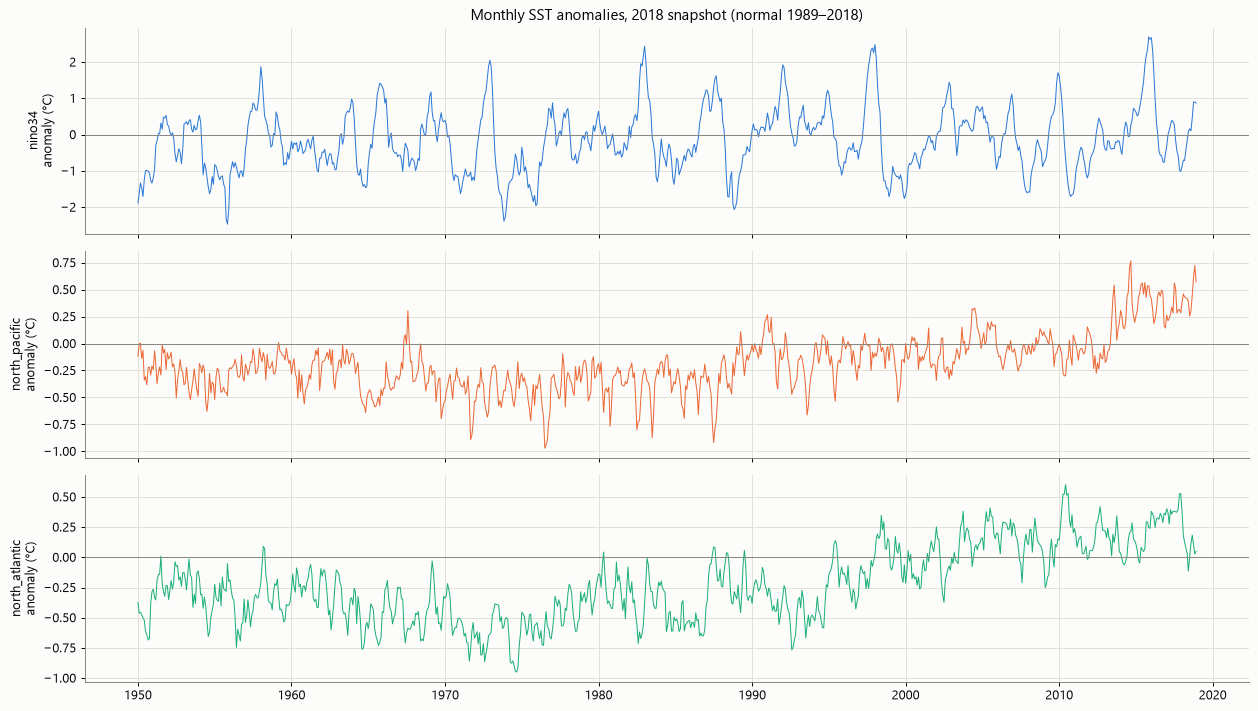

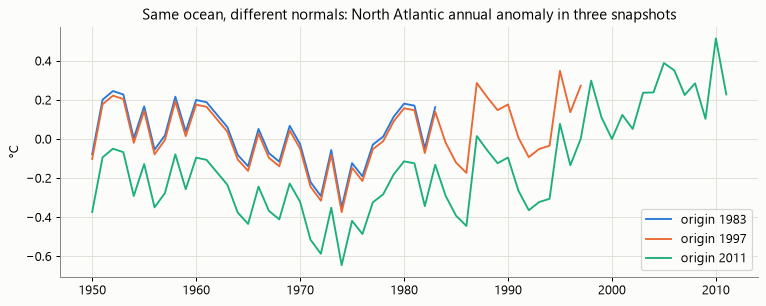

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for ax, index, color in zip(axes, ce.INDICES, SERIES):
    ax.plot(latest["date"], latest[f"{index}_anomaly_c"], color=color, lw=0.8)
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set_ylabel(f"{index}\nanomaly (°C)")
axes[0].set_title("Monthly SST anomalies, 2018 snapshot (normal 1989–2018)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 3.6))
for origin, color in zip((1983, 1997, 2011), SERIES):
    a = pd.read_csv(V2 / f"ocean/origin-{origin}/annual.csv")
    ax.plot(a["year"], a["north_atlantic_anomaly_c"], color=color, label=f"origin {origin}")
ax.set_title("Same ocean, different normals: North Atlantic annual anomaly in three snapshots")
ax.set_ylabel("°C")
ax.legend()
plt.show()

The three snapshots give the same curve shifted up or down. A later origin's normal is warmer, so the same year looks
cooler. A model trained at an origin must read **that origin's** snapshot only. Mixing snapshots would put the
same year on different scales and, for early origins, bring in later normals.

All three boxes warm by 0.08–0.10 °C per decade, so the anomalies include that trend as well as natural swings like
El Niño. They are not pure measures of natural variability.

## 6. Ocean indices: checks for flaws

In [12]:
report = ce.verify_ocean(V2)
for line in report["checks"]:
    print("passes:", line)
print("largest difference from the stored grid (°C):", {k: f"{v:.1e}" for k, v in report["grid_max_error_c"].items()})
print("months with robust |z| > 4 (kept):", report["extreme_anomalies_latest"])
print("warming trend (°C/decade):", report["warming_trend_c_per_decade"])
display(pd.DataFrame(report["anomaly_correlation_latest"]))

passes: no row or date after the origin
passes: no gap, duplicate or missing value
passes: absolute SST identical in every snapshot
passes: box means recomputed from the stored ERSSTv5 grid
passes: anomaly = SST minus the 30-year monthly climatology ending at the origin
passes: annual values = mean of the 12 monthly values
largest difference from the stored grid (°C): {'nino34': '2.6e-06', 'north_pacific': '3.4e-05', 'north_atlantic': '5.2e-06'}
months with robust |z| > 4 (kept): {'nino34': [], 'north_pacific': [['2014-08-01', 0.71, 4.12], ['2014-09-01', 0.767, 4.38], ['2018-11-01', 0.724, 4.19]], 'north_atlantic': []}
warming trend (°C/decade): {'nino34': 0.078, 'north_pacific': 0.075, 'north_atlantic': 0.101}


,nino34_anomaly_c,north_pacific_anomaly_c,north_atlantic_anomaly_c
nino34_anomaly_c,1.000,0.230,0.170
north_pacific_anomaly_c,0.230,1.000,0.720
north_atlantic_anomaly_c,0.170,0.720,1.000


**Every ocean check passes.** I rebuilt the indices from the stored ERSSTv5 grid, and they match to within 0.00004 °C. Each
anomaly equals its SST minus that origin's 30-year monthly normal, and each annual value is the mean of its 12 months.
No row or date comes after its origin, and no month is missing or duplicated. The Niño 3.4 grid snapshot has one extra
latitude row (6° S), outside the box. The published index leaves it out, which is correct.

The only outliers are three North Pacific months (Aug–Sep 2014 and Nov 2018). These are the well-documented marine heat
wave ("the Blob"), so they are real and are kept. The North Pacific and North Atlantic anomalies correlate at 0.72, mostly
through their shared warming trend, so a model using both should expect them to overlap.

**Action:** none on the values. The cleaned release ships this check (`checks/enhance-ocean-verification.json`). It does
not copy the ocean files: they stay in `enhance-v2`, which keeps its exploratory flag.

## 7. Do the ocean indices relate to next year's weather?

At an origin we know the ocean only up to December of that year. The relevant question is whether **this year's** ocean
says anything about **next year's** weather, compared with last year's weather alone. The test: the average over cities of
each target's departure from its 30-year mean, against the previous year's annual anomaly in each box. Years 1955–2004,
2004 snapshot (normal 1975–2004).

In [13]:
a2004 = pd.read_csv(V2 / "ocean/origin-2004/annual.csv").set_index("year")
lab = labels[labels["year"] >= 1925]
national = {}
for metric in METRICS:
    w = lab.pivot(index="year", columns="city_id", values=metric)
    normal = w.rolling(30, min_periods=20).mean().shift(1)     # each year against the 30 years before it
    national[metric] = (w - normal).mean(axis=1)
national = pd.DataFrame(national).loc[1955:EXPLORE_END]
rows = []
for index in ce.INDICES:
    prev = a2004[f"{index}_anomaly_c"].shift(1).reindex(national.index)   # ocean of the year before
    for metric in METRICS:
        rows.append({"index": index, "metric": metric, "previous year (usable)": prev.corr(national[metric]),
                     "persistence: last year's weather": national[metric].shift(1).corr(national[metric])})
display(pd.DataFrame(rows).pivot(index="metric", columns="index", values="previous year (usable)")
        .style.format("{:+.2f}").set_caption("Correlation with the previous year's ocean anomaly, 1955–2004"))
display(pd.DataFrame(rows).groupby("metric")["persistence: last year's weather"].first().round(2).to_frame())

index,nino34,north_atlantic,north_pacific
metric,,,
annual_avg_temp,+0.23,+0.26,+0.24
cdd,+0.28,+0.21,+0.08
hottest_day_temp,+0.23,+0.03,-0.14
total_precip_in,+0.24,-0.31,-0.00


,persistence: last year's weather
metric,
annual_avg_temp,0.440
cdd,0.150
hottest_day_temp,0.080
total_precip_in,0.160


There are 50 years of averages over all cities, so a correlation needs to be beyond about ±0.28 to differ from zero at the
5 % level, and more than that given the trend both series share. Every correlation here is between 0.2 and 0.3 in size:
borderline at best.

- **Average temperature:** about +0.24 for each box, below the +0.44 of last year's weather alone. The ocean is unlikely to
  add much here, and part of what it shows is the shared warming trend.
- **CDD (+0.28 Niño 3.4), hottest day (+0.23 Niño 3.4) and precipitation (−0.31 North Atlantic):** larger than
  persistence (0.15, 0.08 and 0.16). These are the leads worth testing, the more so because 30-year averages beat every
  model on precipitation and the hottest day so far.

These are national averages, and El Niño effects differ by region, so the real test is a city-level model through
`line.py score`. Because `enhance-v2` is not gate-eligible, that score would be exploratory.

## 8. The cleaning step

`clean_static` writes the model-ready city table. The original values keep their own names, and each change or flag is one
row in the issue log. Below are its result and the log.

In [14]:
clean, log, summary = ce.clean_static(static, cities)
print(f"{summary['rows']} cities; dropped {len(summary['constant_columns_dropped'])} constant columns; "
      f"{summary['resolution_converted']} resolutions converted; {summary['elevation_catalog_disagrees']} elevation flags; "
      f"location uncertain: {summary['location_uncertain']}")
print("Model columns:", summary["model_columns"])
print("Treat as categories:", summary["categorical_columns"])
display(log.groupby(["issue", "action"]).size().rename("rows").to_frame())
display(clean.head())

210 cities; dropped 6 constant columns; 15 resolutions converted; 15 elevation flags; location uncertain: ['CorpusChristi', 'LosAngeles', 'Chicago']
Model columns: ['lat', 'lon', 'elevation_m', 'distance_to_ocean_coast_km', 'landcover_station_class', 'landcover_dominant_class_1km', 'landcover_tree_fraction_1km', 'landcover_shrub_fraction_1km', 'landcover_grass_fraction_1km', 'landcover_cropland_fraction_1km', 'landcover_built_fraction_1km', 'landcover_bare_fraction_1km', 'landcover_water_fraction_1km', 'landcover_wetland_fraction_1km', 'landcover_mangrove_fraction_1km']
Treat as categories: ['landcover_station_class', 'landcover_dominant_class_1km']


,,rows
issue,action,
catalog elevation differs by > 30 m,flagged; elevation_m (USGS) kept,15
constant column,dropped,6
coordinate > 3 km from catalog station,"flagged; elevation, coast distance and land cover may describe the wrong point",3
resolution in degrees,converted to metres,15


,city_id,name,lat,lon,station_catalog_lat,station_catalog_lon,station_catalog_elevation_m,elevation_coordinate_offset_km,elevation_m,elevation_resolution_m,elevation_acquisition_date,distance_to_ocean_coast_km,landcover_station_class,landcover_dominant_class_1km,landcover_valid_pixels_1km,landcover_tree_fraction_1km,landcover_shrub_fraction_1km,landcover_grass_fraction_1km,landcover_cropland_fraction_1km,landcover_built_fraction_1km,landcover_bare_fraction_1km,landcover_water_fraction_1km,landcover_wetland_fraction_1km,landcover_mangrove_fraction_1km,elevation_catalog_diff_m,elevation_catalog_disagrees,location_uncertain
0,USC00042863,Escondido,33.121,-117.090,33.121,-117.090,182.900,0.000,196.398,1.000,unknown,21.212,50,50,43692,0.046,0.000,0.016,0.000,0.913,0.025,0.000,0.000,0.000,13.498,False,False
1,USC00166584,Natchitoches,31.814,-93.086,31.814,-93.086,43.000,0.000,42.254,1.000,2018-09-05,214.173,10,10,43052,0.592,0.000,0.217,0.012,0.018,0.003,0.157,0.002,0.000,-0.746,False,False
2,USC00280734,Belvidere,40.829,-75.083,40.829,-75.083,80.200,0.000,78.838,1.000,2019-10-06,75.921,50,10,48340,0.632,0.000,0.121,0.071,0.081,0.001,0.093,0.000,0.000,-1.362,False,False
3,USC00286055,NewBrunswick,40.473,-74.422,40.473,-74.422,33.800,0.000,20.902,1.000,2025-08-04,12.135,30,10,48090,0.557,0.000,0.194,0.036,0.145,0.000,0.067,0.000,0.000,-12.898,False,False
4,USC00356749,Portland,45.518,-122.689,45.518,-122.689,48.500,0.000,39.708,1.000,unknown,80.711,50,50,52228,0.379,0.000,0.001,0.000,0.617,0.002,0.002,0.000,0.000,-8.792,False,False


## 9. Findings

| Part | Flaw | Evidence | Action |
|---|---|---|---|
| city facts | 6 constant columns | one value for all 210 cities | **dropped** |
| city facts | resolution in degrees | 15 cities at 1/9 or 1/3 arc-second written as degrees | **converted** to metres (3.44 m, 10.31 m) |
| city facts | catalog elevation off | 15 cities differ by more than 30 m with the coordinates 40 m apart; USGS matches the airports' field elevations | **flagged**; use USGS `elevation_m` |
| city facts | coordinate not at the station | Corpus Christi 11.1 km, Los Angeles 6.0 km, Chicago 3.9 km | **flagged** `location_uncertain`; recomputation belongs to the enhance station |
| city facts | class codes, fractions that sum to 1 | codes are categories; the fractions are not independent | documented in the model-column list |
| city facts | describe the 2018 station | station moves in the record | documented; a city-level fact |
| ocean | none in the values | every snapshot recomputed exactly | **unchanged**; verification shipped |
| ocean | reconstruction uses later data | ERSSTv5 is a modern reconstruction | cannot be cleaned: `enhance-v2` stays **exploratory** |
| ocean | anomalies include the warming trend | +0.08–0.10 °C/decade in all boxes | documented; use one origin's snapshot only |

**For model training:**

1. For official scores, use the cleaned city table (`static/city_static_clean.csv` in `clean-v2`, gate-eligible) together
   with the `clean-v1` weather tables that `clean-v2` carries unchanged.
2. Use the ocean indices only from `ocean/origin-<origin>/` of `enhance-v2`, and only for years up to the origin. Runs using
   them are exploratory.
3. Likely features to try, in the feature-engineering step: city facts as inputs to cross-city learners (shared trends,
   CDD response); the previous year's Niño 3.4 anomaly for CDD and the hottest day, and the North Atlantic anomaly for precipitation.